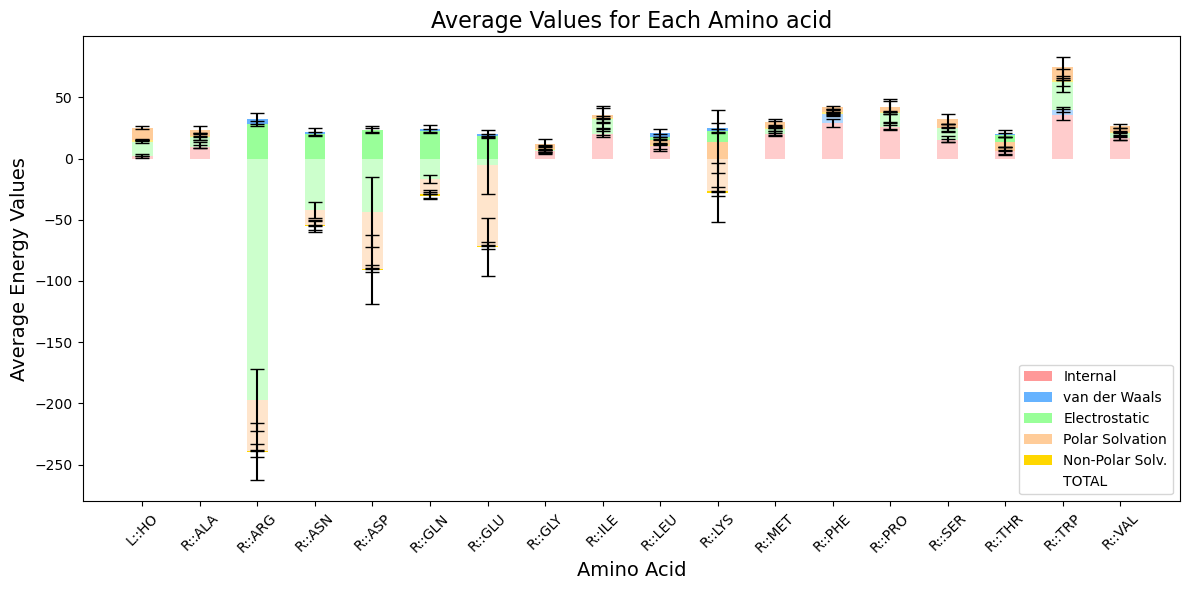

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# بارگذاری دادههای CSV
input_file = 'full_processed_5H2O2-run1.csv'  # نام فایل CSV خود را اینجا قرار دهید
# خواندن دادهها
data = pd.read_csv(input_file)

# محاسبه میانگین و انحراف معیار برای هر Residue
mean_data = data.groupby('Residue').mean()[['TOTAL', 'Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']]
std_data = data.groupby('Residue').std()[['TOTAL', 'Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']]

# بررسی محاسبات Totals
mean_data['Computed TOTAL'] = mean_data[['Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']].sum(axis=1)

# بررسی اختلاف بین TOTAL محاسبه شده و TOTAL موجود
if not mean_data['TOTAL'].equals(mean_data['Computed TOTAL']):
    print("Warning: Computed TOTAL does not match the existing TOTAL column.")

# رسم نمودار میلهای
labels = mean_data.index
x = range(len(labels))  # مختصات سطرها

bar_width = 0.35  # عرض هر میله
fig, ax = plt.subplots(figsize=(12, 6))

# ایجاد میلهها
colors = ['#FF9999', '#66B3FF', '#99FF99', '#FFCC99', '#FFD700']  # رنگها برای هر بار
bottoms = [0] * len(labels)  # برای قرار دادن میلهها روی هم

# رسم میلهها برای هر یک از ستونهای Internal، van der Waals، Electrostatic، Polar Solvation و Non-Polar Solv.
for i, col in enumerate(['Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']):
    ax.bar(x, mean_data[col], width=bar_width, label=col, bottom=bottoms, color=colors[i],
           yerr=std_data[col], capsize=5)  # افزودن error bars
    bottoms = [bottom + value for bottom, value in zip(bottoms, mean_data[col])]

# افزودن میله Totals در یک رنگ متفاوت
ax.bar(x, mean_data['TOTAL'], width=bar_width, label='TOTAL', color='white', alpha=0.5,
       yerr=std_data['TOTAL'], capsize=5)  # افزودن error bars برای TOTAL

# افزودن جزئیات به نمودار
ax.set_xlabel('Amino Acid', fontsize=14)
ax.set_ylabel('Average Energy Values', fontsize=14)
ax.set_title('Average Values for Each Amino acid', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45)
ax.legend()

# نمایش نمودار
plt.tight_layout()
plt.savefig('Average Values 1.png',dpi=1000)
plt.show()

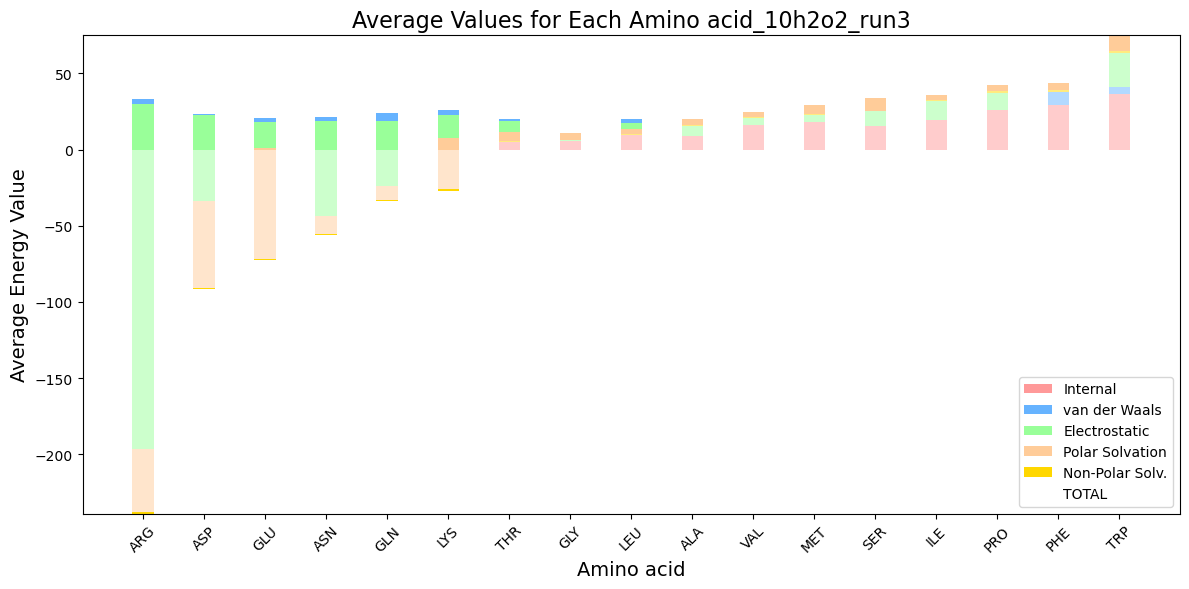

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# بارگذاری دادههای CSV
input_file = r"C:\Users\Lenovo\Desktop\New folder\FINAL_DECOMP_MMPBSA_run3.csv" # نام فایل CSV خود را اینجا قرار دهید

# خواندن دادهها
data = pd.read_csv(input_file)
# مرتب‌سازی داده‌ها
data = data.sort_values(by='TOTAL', ascending=True) 
data =data[~data['Residue'].str.contains('L::H2O2', case=False, na=False)]
data =data[~data['Residue'].str.contains('L::H', case=False, na=False)]
data['Residue']=data['Residue'].str.replace('R::','',regex=False)
data['Residue']=data['Residue'].str.replace(':','',regex=False)
data['Residue']=data['Residue'].str.replace('::','',regex=False)

# استخراج نام بدون عدد
data['Residue'] = data['Residue'].apply(lambda x: re.split(r'\d+', x)[0])

#df_sorted.to_csv("cleaned_data_RUN3.csv", index=False)
# محاسبه میانگین برای هر Residue
mean_data = data.groupby('Residue').mean()[['TOTAL', 'Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']]

# بررسی محاسبات Totals
mean_data['Computed TOTAL'] = mean_data[['Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']].sum(axis=1)

# بررسی اختلاف بین TOTAL محاسبه شده و TOTAL موجود
if not mean_data['TOTAL'].equals(mean_data['Computed TOTAL']):
    print("Warning: Computed TOTAL does not match the existing TOTAL column.")
mean_data=mean_data.sort_values('TOTAL',ascending=True)
# رسم نمودار میلهای
labels = mean_data.index
x = range(len(labels))  # مختصات سطرها

bar_width = 0.35  # عرض هر میله
fig, ax = plt.subplots(figsize=(12, 6))

# ایجاد میلهها
colors = ['#FF9999', '#66B3FF', '#99FF99', '#FFCC99', '#FFD700']  # رنگها برای هر بار
bottoms = [0] * len(labels)  # برای قرار دادن میلهها روی یکدیگر

# رسم میلهها برای هر یک از ستونهای Internal، van der Waals، Electrostatic، Polar Solvation و Non-Polar Solv.
for i, col in enumerate(['Internal', 'van der Waals', 'Electrostatic', 'Polar Solvation', 'Non-Polar Solv.']):
    ax.bar(x, mean_data[col], width=bar_width, label=col, bottom=bottoms, color=colors[i])
    bottoms = [bottom + value for bottom, value in zip(bottoms, mean_data[col])]

# افزودن میله Totals در یک رنگ متفاوت
ax.bar(x, mean_data['TOTAL'], width=bar_width, label='TOTAL', color='white', alpha=0.5)

# افزودن جزئیات به نمودار
ax.set_xlabel('Amino acid', fontsize=14)
ax.set_ylabel('Average Energy Value', fontsize=14)
ax.set_title('Average Values for Each Amino acid_10h2o2_run3', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45)
ax.legend()

# نمایش نمودار
plt.tight_layout()
plt.savefig('Average Values 1 without error_10h2o2_run 3.png',dpi=1000)
plt.show()
